In [1]:
# Step 1: Import necessary libraries
import pandas as pd
import numpy as np


In [2]:
# Step 2: Load the dataset
df = pd.read_csv("bangalore house price.csv")
print(df.shape)


(7120, 108)


In [3]:
df.head()

,bath,balcony,price,total_sqft_int,bhk,price_per_sqft,area_typeSuper built-up Area,area_typeBuilt-up Area,area_typePlot Area,availability_Ready To Move,...,location_Kalena Agrahara,location_Horamavu Agara,location_Vidyaranyapura,location_BTM 2nd Stage,location_Hebbal Kempapura,location_Hosur Road,location_Horamavu Banaswadi,location_Domlur,location_Mahadevpura,location_Tumkur Road
0,3.0,2.0,150.0,1672.0,3,8971.291866,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,3.0,3.0,149.0,1750.0,3,8514.285714,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,3.0,2.0,150.0,1750.0,3,8571.428571,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,2.0,2.0,40.0,1250.0,2,3200.000000,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,2.0,2.0,83.0,1200.0,2,6916.666667,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0


In [4]:
# Step 3: Define features and target
X = df.drop(columns=['price'])  # All columns except the target
y = df['price']



*   A target column "price"

*   107 independent variables (e.g., bath, total_sqft_int, location dummy variables)




In [5]:

# Step 4: Split into train and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [6]:
# Step 5: Standardize and apply Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lr_pipeline = make_pipeline(StandardScaler(), LinearRegression())
lr_pipeline.fit(X_train, y_train)


,steps,"[('standardscaler', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


We create a pipeline to standardize features and apply Linear Regression.

*   StandardScaler() makes all features have mean 0 and variance 1.
*   Linear regression is then trained on scaled data.



In [7]:
# Evaluate Linear Regression
y_train_pred = lr_pipeline.predict(X_train)
y_test_pred = lr_pipeline.predict(X_test)

from sklearn.metrics import r2_score
print("Linear Regression:")
print("Train R²:", r2_score(y_train, y_train_pred))
print("Test R² :", r2_score(y_test, y_test_pred))

Linear Regression:
Train R²: 0.8439925248308796
Test R² : 0.9196808132211589


In [8]:
# Step 6: Apply ShuffleSplit Cross-Validation
from sklearn.model_selection import ShuffleSplit, cross_val_score

shuffle_split = ShuffleSplit(n_splits=100, test_size=0.2, random_state=42)
cv_scores = cross_val_score(lr_pipeline, X, y, cv=shuffle_split, scoring='r2')
#print("Cross-Validation R² Scores:", cv_scores)
print("Average CV R²:", np.round(cv_scores.mean(),2))


Average CV R²: 0.86


We apply ShuffleSplit, a kind of cross-validation that:

Randomly shuffles the data

*   Performs 5 different train-test splits
*   Reports R² scores on each split
*   This helps verify the model's consistency and generalization.


In [9]:
# Step 7: Apply LassoCV to find optimal alpha
from sklearn.linear_model import Lasso, LassoCV

lasso_cv_pipeline = make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=10000,alphas = None))
lasso_cv_pipeline.fit(X_train, y_train)

C:\Users\ExcelR Trainers\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1641: FutureWarning: 'alphas=None' is deprecated and will be removed in 1.9, at which point the default value will be set to 100. Set 'alphas=100' to silence this warning.
  warnings.warn(


,steps,"[('standardscaler', ...), ('lassocv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,eps,0.001
,n_alphas,'deprecated'
,alphas,None
,fit_intercept,True


1. scikit-learn automatically sets alphas=None, which then triggers this logic inside LassoCV:

  “If alphas is None, use 100 values on a log scale between alpha_max and alpha_max * eps, where eps=0.001

2. max_iter=100, it defaults to 100 iterations (in scikit-learn). But if the loss hasn’t converged in 100 steps, you’ll get warning, hence better to keep highest number

In [10]:

print("All alphas tried by LassoCV:", lasso_cv_pipeline.named_steps['lassocv'].alphas_)


All alphas tried by LassoCV: [93.80009819 87.47828551 81.58254184 76.08415157 70.9563344  66.17411494
 61.71420107 57.55487047 53.67586483 50.05829119 46.6845299  43.53814883
 40.60382332 37.86726152 35.31513483 32.93501294 30.7153033  28.64519466
 26.71460441 24.91412948 23.23500054 21.66903927 20.20861855 18.84662529
 17.57642582 16.39183355 15.28707883 14.25678088 13.29592157 12.39982095
 11.56411452 10.78473191 10.05787707  9.38000982  8.74782855  8.15825418
  7.60841516  7.09563344  6.61741149  6.17142011  5.75548705  5.36758648
  5.00582912  4.66845299  4.35381488  4.06038233  3.78672615  3.53151348
  3.29350129  3.07153033  2.86451947  2.67146044  2.49141295  2.32350005
  2.16690393  2.02086185  1.88466253  1.75764258  1.63918336  1.52870788
  1.42567809  1.32959216  1.2399821   1.15641145  1.07847319  1.00578771
  0.93800098  0.87478286  0.81582542  0.76084152  0.70956334  0.66174115
  0.61714201  0.5755487   0.53675865  0.50058291  0.4668453   0.43538149
  0.40603823  0.378672

In [11]:
# Extract best alpha
best_alpha = lasso_cv_pipeline.named_steps['lassocv'].alpha_
print("Best alpha from LassoCV:", best_alpha)

Best alpha from LassoCV: 0.17576425824625858


In [12]:
# Evaluate performance with best alpha
y_train_lasso = lasso_cv_pipeline.predict(X_train)
y_test_lasso = lasso_cv_pipeline.predict(X_test)
print("LassoCV Train R²:", np.round(r2_score(y_train, y_train_lasso)*100,2))
print("LassoCV Test R² :", np.round(r2_score(y_test, y_test_lasso)*100,2))

LassoCV Train R²: 84.37
LassoCV Test R² : 91.89


In [13]:
# Step 8: Plot alpha vs CV error
mse_path = lasso_cv_pipeline.named_steps['lassocv'].mse_path_.mean(axis=1)
alphas_tested = lasso_cv_pipeline.named_steps['lassocv'].alphas_
alphas_tested

array([93.80009819, 87.47828551, 81.58254184, 76.08415157, 70.9563344 ,
       66.17411494, 61.71420107, 57.55487047, 53.67586483, 50.05829119,
       46.6845299 , 43.53814883, 40.60382332, 37.86726152, 35.31513483,
       32.93501294, 30.7153033 , 28.64519466, 26.71460441, 24.91412948,
       23.23500054, 21.66903927, 20.20861855, 18.84662529, 17.57642582,
       16.39183355, 15.28707883, 14.25678088, 13.29592157, 12.39982095,
       11.56411452, 10.78473191, 10.05787707,  9.38000982,  8.74782855,
        8.15825418,  7.60841516,  7.09563344,  6.61741149,  6.17142011,
        5.75548705,  5.36758648,  5.00582912,  4.66845299,  4.35381488,
        4.06038233,  3.78672615,  3.53151348,  3.29350129,  3.07153033,
        2.86451947,  2.67146044,  2.49141295,  2.32350005,  2.16690393,
        2.02086185,  1.88466253,  1.75764258,  1.63918336,  1.52870788,
        1.42567809,  1.32959216,  1.2399821 ,  1.15641145,  1.07847319,
        1.00578771,  0.93800098,  0.87478286,  0.81582542,  0.76

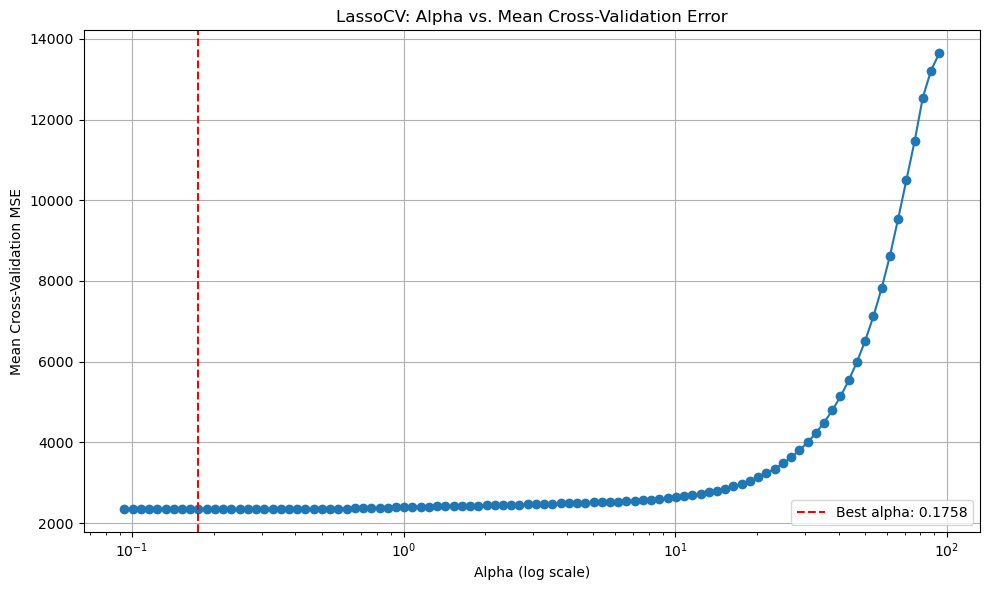

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(alphas_tested, mse_path, marker='o')
plt.axvline(best_alpha, color='red', linestyle='--', label=f'Best alpha: {best_alpha:.4f}')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Mean Cross-Validation MSE')
plt.title('LassoCV: Alpha vs. Mean Cross-Validation Error')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



*   We plot the mean cross-validation error (MSE) against different alphas.

*   A red line shows the best alpha (0.1758 in this case).
* Helps visually confirm the best tradeoff between bias and variance.






In [15]:
# Step 9: Feature selection — count zeroed coefficients
lasso_model = lasso_cv_pipeline.named_steps['lassocv']
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso_model.coef_
})
zeroed_features = coef_df[coef_df['Coefficient'] == 0]
print("Number of features removed by LassoCV:", len(zeroed_features))


Number of features removed by LassoCV: 14


In [16]:
coef_df.head(20)

,Feature,Coefficient
0,bath,0.238021
1,balcony,-0.010586
2,total_sqft_int,80.627350
3,bhk,-10.516459
4,price_per_sqft,63.578564
5,area_typeSuper built-up Area,1.265992
6,area_typeBuilt-up Area,-0.000000
7,area_typePlot Area,-1.939414
8,availability_Ready To Move,-1.924862
9,location_Whitefield,-3.115894






*   We examine which coefficients were set to zero by Lasso.
*   These features are considered not useful
*   Lasso at α = 0.1758 removed 14 features (i.e., retained 93)




In [17]:
# Step 10: Test with higher alpha to simplify model
for alpha_val in [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1]:
    lasso_custom = make_pipeline(StandardScaler(), Lasso(alpha=alpha_val, max_iter=10000))
    lasso_custom.fit(X_train, y_train)

    y_test_pred = lasso_custom.predict(X_test)
    r2_test = r2_score(y_test, y_test_pred)
    non_zero_count = sum(lasso_custom.named_steps['lasso'].coef_ != 0)

    print(f"\nAlpha: {alpha_val}")
    print(f"Test R²: {r2_test:.4f}")
    print(f"Retained Features: {non_zero_count}")


Alpha: 0.1
Test R²: 0.9193
Retained Features: 102

Alpha: 0.2
Test R²: 0.9188
Retained Features: 90

Alpha: 0.3
Test R²: 0.9179
Retained Features: 81

Alpha: 0.4
Test R²: 0.9169
Retained Features: 75

Alpha: 0.5
Test R²: 0.9158
Retained Features: 70

Alpha: 0.6
Test R²: 0.9145
Retained Features: 62

Alpha: 0.7
Test R²: 0.9132
Retained Features: 54

Alpha: 0.8
Test R²: 0.9120
Retained Features: 49

Alpha: 0.9
Test R²: 0.9107
Retained Features: 44

Alpha: 1
Test R²: 0.9096
Retained Features: 38


In [18]:
# Step 11: Final model with alpha = 0.2 (recommended)
final_alpha = 0.2
final_lasso = make_pipeline(StandardScaler(), Lasso(alpha=final_alpha, max_iter=10000))
final_lasso.fit(X_train, y_train)

final_coef = final_lasso.named_steps['lasso'].coef_
selected_features = X.columns[final_coef != 0]
print("\nFinal Selected Features (alpha = 0.2):", len(selected_features))


Final Selected Features (alpha = 0.2): 90


In [19]:
# Final evaluation
y_train_final = final_lasso.predict(X_train)
y_test_final = final_lasso.predict(X_test)

print("Final Lasso Train R²:", np.round(r2_score(y_train, y_train_final)*100,2))
print("Final Lasso Test R² :", np.round(r2_score(y_test, y_test_final)*100,2))

Final Lasso Train R²: 84.36
Final Lasso Test R² : 91.88


In [20]:
# prompt: print the feature names which are finalized from above after using alpha as 0.9

selected_features

Index(['total_sqft_int', 'bhk', 'price_per_sqft',
       'area_typeSuper built-up  Area', 'area_typePlot  Area',
       'availability_Ready To Move', 'location_Whitefield',
       'location_Sarjapur  Road', 'location_Electronic City',
       'location_Marathahalli', 'location_Raja Rajeshwari Nagar',
       'location_Haralur Road', 'location_Hennur Road',
       'location_Bannerghatta Road', 'location_Uttarahalli',
       'location_Thanisandra', 'location_Electronic City Phase II',
       'location_Hebbal', 'location_7th Phase JP Nagar', 'location_Yelahanka',
       'location_KR Puram', 'location_Sarjapur', 'location_Rajaji Nagar',
       'location_Kasavanhalli', 'location_Bellandur', 'location_Begur Road',
       'location_Banashankari', 'location_Kothanur', 'location_Hormavu',
       'location_Harlur', 'location_Jakkur',
       'location_Electronics City Phase 1', 'location_Varthur',
       'location_Chandapura', 'location_Hennur', 'location_Ramamurthy Nagar',
       'location_Kaggada

In [32]:
X.columns[final_coef == 0]

Index(['bath', 'balcony', 'area_typeBuilt-up  Area', 'location_Kanakpura Road',
       'location_Akshaya Nagar', 'location_HSR Layout',
       'location_Ramagondanahalli', 'location_Hulimavu', 'location_Budigere',
       'location_Vittasandra', 'location_Sahakara Nagar', 'location_Hosa Road',
       'location_Devanahalli', 'location_Kanakapura',
       'location_5th Phase JP Nagar', 'location_TC Palaya',
       'location_CV Raman Nagar'],
      dtype='object')

In [43]:
from sklearn.linear_model import Ridge
ridge=Ridge(alpha=0.17)

ridge.fit(X_train,y_train)

,alpha,0.17
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [44]:
y_train_pred=ridge.predict(X_train)
y_test_pred=ridge.predict(X_test)

In [45]:
print(r2_score(y_train,y_train_pred))
print(r2_score(y_test,y_test_pred))

0.8439918816121845
0.9196592290041485
